In [ ]:
#importing libraries
import pandas as pd
import graphviz
import math
import numpy as np
import random
np.random.seed(7) # fix random seed for reproducibility
from keras.models import Sequential
from keras.layers import Dense, Embedding
from keras.layers import LSTM
from matplotlib import pyplot as plt
from keras.preprocessing.text import Tokenizer
from keras.layers import Dropout
from keras.preprocessing.sequence import pad_sequences
from keras.utils.vis_utils import plot_model
import pydotplus as pydot

from graphviz import Digraph
import copy

In [ ]:
# # mount drive
# from google.colab import drive
# drive.mount('/content/gdrive')

In [ ]:
class helper:
  def __init__(self):
    self.i= 0
  # def datasetListMergeMinus(self, dataset, subset):
  #   wholeData = 1
  #   for m in dataset:
  #     if not m.equals(subset):
  #       if type(wholeData) is int:
  #         wholeData = m
  #       else:
  #         wholeData = wholeData.append(m)
  #   return wholeData
  def multiDimStrToUpper(self, string):
    nstring = []
    for strns in string:
      nstring.append([x.upper() for x in strns])
    return nstring
  def multiDimStrToLower(self, string):
    nstring = []
    for strns in string:
      nstring.append([x.lower() for x in strns])
    return nstring
  def oneDimStrToLower(self, string):
    nstring = []
    for i in range(0, len(string)):
      nstring.append(string[i].lower())
    return nstring
  def grabEventsFromHeader(self, header):
    evs = []
    c = 0
    for ev in header:
      if c > 0:
        try:
          num = int(ev)
        except:
          evs.append(ev)
      c = c + 1
    return evs
  def rowIsFirst(self, row, activities, headers):
    foundValues = [];
    for i in range(0,len(headers)):
      val = headers[i]
      if row[val] in activities:
        foundValues.append(row[val])
    if (len(foundValues) == 0):
      return True
    return False

  def rowIsLast(self, row, evName):
    rowEv = row.idxmax()
    try:
      if rowEv.lower() == evName.lower():
        return True
    except:
      return False
    return False

  def divideMatrix(self, matrix):
    headers = list(matrix.columns.values)
    leftHeaders = []
    rightHeaders = []
    for i in range(0,len(headers)):
      ev = headers[i]
      try:
          num = int(ev)
          leftHeaders.append(ev)
      except:
          rightHeaders.append(ev)
    leftData = matrix[leftHeaders]
    rightData = matrix[rightHeaders]
    return [leftData, rightData]

In [ ]:
class prepareData:
  def __init__(self, data, label):
    self.data = data
    self.label = label
  def create_input_output(self, xy):
    # Define Empty List
    values = []
    xList = [];
    _ncols = ('X', 'Y')
    values.append(("NULL", xy[0]))
    i = 0
    while i < len(xy):
        try:
            xList = xy[0: i+1]
            xList.insert(0, "NULL")
            values.append((xList, xy[i + 1]))
        except:
            xList = xy[0: i+1]
            xList.insert(0, "NULL")
            values.append((xList, "END"))
        i = i + 1
    return pd.DataFrame(values, columns=_ncols)

  def prepare(self, validEvts = None, test_size = 0):
    nameLabel = self.label[0]
    valueLabel = self.label[1]
    _activeCase = "NULL"
    _tempxy = []
    _ncols = ('X', 'Y')
    maindfObj = pd.DataFrame([], columns=_ncols)
    maindfObjChunks = []
    if validEvts is not None:
      helperObj = helper()
      validEvts = helperObj.oneDimStrToLower(validEvts)
    for index, row in self.data.iterrows():
      if validEvts is not None and row[valueLabel].lower() not in validEvts:
        continue
      if nameLabel in row and (row[nameLabel] == _activeCase or _activeCase == "NULL"):
        concatenatedString = row[valueLabel]
        _tempxy.append(concatenatedString)
        _activeCase = row[nameLabel]
      else:
        subObject = self.create_input_output(_tempxy)
        maindfObj = maindfObj.append(subObject)
        maindfObjChunks.append(subObject)
        _activeCase = row[nameLabel]
        _tempxy.clear()
        concatenatedString = row[valueLabel]
        _tempxy.append(concatenatedString)
    self.tokenize(maindfObj)
    self.maindfObj = maindfObj
    self.maindfObjChunks = maindfObjChunks
    return self.custom_split(self.X, self.Y, test_size)

  def append_to_2d(self, former_2d, new_2d):
    for i in range(len(new_2d)):
      former_2d.append(new_2d[i])
    return former_2d

  def custom_split(self, X, Y, test_size):
    Xtrain = []
    Ytrain = []
    Xtest = []
    Ytest = []
    _ncols = ('X', 'Y')
    maindfObjTrain = pd.DataFrame([], columns=_ncols)
    maindfObjTest = pd.DataFrame([], columns=_ncols)
    size = X.shape
    import random
    startList = [];
    endList = [];
    for i in range(size[0]):
      consid = X[i]
      if consid[len(consid) - 2] == 0:
        startList.append(i)
        if(i > 0):
          endList.append(i-1)
    endList.append(size[0]-1) #Tail End of the Array is the last element of endList
    num_test = int(round(len(startList)*test_size))
    num_train = len(startList) - num_test
    t = random.sample(startList, num_test)
    counter = 0
    for i in startList:
      Xcase = np.array(X[i:endList[counter]+1])
      Ycase = np.array(Y[i:endList[counter]+1])
      if (i in t):
        Xtest = self.append_to_2d(Xtest, Xcase)
        Ytest = self.append_to_2d(Ytest, Ycase)
        maindfObjTest = maindfObjTest.append(self.maindfObjChunks[counter])
      else:
        Xtrain = self.append_to_2d(Xtrain, Xcase)
        Ytrain = self.append_to_2d(Ytrain, Ycase)
        maindfObjTrain = maindfObjTrain.append(self.maindfObjChunks[counter])
      counter = counter + 1
      self.maindfObjTest = maindfObjTest
      self.maindfObjTrain = maindfObjTrain
    return np.array(Xtrain), np.array(Xtest), np.array(Ytrain), np.array(Ytest)

  def tokenize(self, data):
    tokenizer = Tokenizer(filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n')
    tokenizer.fit_on_texts(data['X'])
    X = tokenizer.texts_to_sequences(data['X'])
    word_index = tokenizer.word_index
    print(word_index)
    print('Found %s unique tokens.' % len(word_index))
    X = pad_sequences(X)
    Y = pd.get_dummies(data['Y'])
    self.X = X
    self.Y = Y
    print(X.shape)
    print(Y.shape)
    self.tokenizer = tokenizer


In [ ]:
class resultGraphing:
  def __init__(self):
    self.i= 0
  def decomposeResult(self, results):
    helper_ = helper()
    headers = list(results.columns.values)
    events = helper_.grabEventsFromHeader(headers)
    matrices = []
    matricesLeft = []
    lastIndex = -1
    totalBegin = 0
    ind = 0
    newMatrix = helper_.divideMatrix(results)
    for index, row in results.iterrows():
      ind = index
      if helper_.rowIsFirst(row, events, headers):
        totalBegin = totalBegin + 1
        if lastIndex > -1:
          if lastIndex == 0:
            sequenceList = newMatrix[1].iloc[lastIndex:index, :]
            sequenceListLeft = newMatrix[0].iloc[lastIndex:index, :]
            matrices.append(sequenceList)
            matricesLeft.append(sequenceListLeft)
          else:
            sequenceList = newMatrix[1].iloc[lastIndex+1:index, :]
            sequenceListLeft = newMatrix[0].iloc[lastIndex+1:index, :]
            matrices.append(sequenceList)
            matricesLeft.append(sequenceListLeft)
        if index < 1:
          lastIndex = index
        else:
          lastIndex = index - 1
    sequenceList = newMatrix[1].iloc[lastIndex+1:ind+1, :]
    sequenceListLeft = newMatrix[0].iloc[lastIndex+1:ind+1, :]
    matrices.append(sequenceList)
    matricesLeft.append(sequenceListLeft)
    return matrices, matricesLeft

  def decomposeResultProbBias(self, results):
    helper_ = helper()
    headers = list(results.columns.values)
    events = helper_.grabEventsFromHeader(headers)
    matrices = []
    matricesLeft = []
    lastIndex = 0
    totalBegin = 0
    ind = 0
    newMatrix = helper_.divideMatrix(results)
    for index, row in newMatrix[1].iterrows():
      ind = index
      rowIsLast = helper_.rowIsLast(row, "end")
      if rowIsLast:
        sequenceList = newMatrix[1].iloc[lastIndex:index+1, :]
        sequenceListLeft = newMatrix[0].iloc[lastIndex:index+1, :]
        matrices.append(sequenceList)
        matricesLeft.append(sequenceListLeft)
        lastIndex = index + 1
    return matrices, matricesLeft

  def rowIsAnewSequence(self, row):
    try:
      return math.isnan(row["1"])
    except:
      return False
  # def chopBySequence(self, matrix):
  #   startIndex = []
  #   stopIndex = []
  #   for index, row in matrix.iterrows():
  #     if(self.rowIsAnewSequence(row)):
  #       if(index == 0):
  #         startIndex.append(index)
  #       else:
  #         startIndex.append(index)
  #         stopIndex.append(index-1)
  #   stopIndex.append(index)
  #   return startIndex, stopIndex

  def linkAndProbabilities(self, matrices, count = 0):
    links = []
    probabilities = []
    sequences = []
    uniqueEvs = []
    for i in range(0,len(matrices)):
      thisMatrix = matrices[i]
      lastEvent = "Start";
      sequence = []
      for index, row in thisMatrix.iterrows():
        row = pd.to_numeric(row)
        #print(row) # prints the rows
        evName = row.idxmax(axis=1) # picks event with the highest probability
        link = lastEvent + "<-->" + evName
        sequence.append(evName)
        if link not in links:
          if lastEvent != evName:
            if not (lastEvent.lower() == "start" and evName.lower() == "end"):
              links.append(link)
              prob = row[evName]
              probabilities.append(prob)
        lastEvent = evName
      # The Last element is End and undesirable
      sequence.pop()
      sequences.append(sequence)
    return links, probabilities, sequences

  # def linkAndProbabilities_beta(self, eventMatrix_, probabilityMatrix_, indx = 0):
  #   links = []
  #   probabilities = []
  #   sequences = []
  #   uniqueEvs = []
  #   totalDrifts = 0;
  #   for j in range(0, len(eventMatrix_)):
  #     eventMatrix = eventMatrix_[j]
  #     probabilityMatrix = probabilityMatrix_[j]
  #     x, y = self.chopBySequence(eventMatrix)
  #     lastEvent = "Start";
  #     sequence = []
  #     readEvs = 0
  #     if(indx != None and indx > len(x)):
  #       raise Exception("Index is out of bound of the sequence count")
  #     if indx != None:
  #       interestingSequenceTable = eventMatrix.loc[x[indx]:y[indx], :]
  #       interestingSequenceTable = interestingSequenceTable.reset_index(drop=True)
  #       interestingProbabilityTable = probabilityMatrix.loc[x[indx]:y[indx], :]
  #       interestingProbabilityTable = interestingProbabilityTable.reset_index(drop=True)
  #     else:
  #       interestingSequenceTable = eventMatrix.reset_index(drop=True)
  #       interestingProbabilityTable = probabilityMatrix.reset_index(drop=True)
  #     for index, row in interestingSequenceTable.iterrows():
  #       if(index == 0):
  #         evName = "Start"
  #       else:
  #         evName = row[index]
  #         probability = interestingProbabilityTable.at[index-1, evName]
  #         link = lastEvent + "<-->" + evName
  #         if link not in links:
  #           links.append(link)
  #           probabilities.append(probability)
  #       sequence.append(evName)
  #       lastRow = row
  #       lastEvent = evName
  #   evName = "END"
  #   link = lastEvent + "<-->" + evName
  #   links.append(link)
  #   probability = interestingProbabilityTable.at[index, evName]
  #   probabilities.append(probability)
  #   return links, probabilities, [sequence]

  # def link(self, matrices):
  #   links = []
  #   sequences = []
  #   for i in range(0,len(matrices)):
  #     thisMatrix = matrices[i]
  #     lastEvent = "Start";
  #     sequence = []
  #     for index, row in thisMatrix.iterrows():
  #       if lastEvent == "END":
  #         break
  #       row = pd.to_numeric(row)
  #       evName = row.idxmax(axis=1)
  #       link = lastEvent + "<-->" + evName
  #       sequence.append(evName)
  #       if link not in links:
  #         if lastEvent != evName:
  #           links.append(link)
  #       lastEvent = evName
  #     # The Last element is End and undesirable
  #     sequence.pop()
  #     sequences.append(sequence)
  #   return links, sequences

  # def linkV2(self, matrices):
  #   links = []
  #   sequences = []
  #   for i in range(0,len(matrices)):
  #     thisMatrix = matrices[i]
  #     lastEvent = "Start";
  #     sequence = []
  #     lastRow = thisMatrix.tail(1)
  #     for column in lastRow:
  #       b = lastRow[column]
  #       activity = b.values[0]
  #       nullornan = False
  #       try:
  #         nullornan = activity.upper() == 'NULL'
  #       except:
  #         nullornan = math.isnan(activity)
  #       if nullornan:
  #         continue
  #       elif activity == '':
  #         activity = 'END'
  #       evName = activity
  #       link = lastEvent + "<-->" + evName
  #       sequence.append(evName)
  #       if link not in links:
  #         if lastEvent != evName:
  #           links.append(link)
  #       lastEvent = evName
  #       if activity == 'END':
  #         break
  #     sequence.pop()
  #     sequences.append(sequence)
  #   return links, sequences

  def drawGraph(self, transitions, probabilities, counter = 0):
    G = Digraph('process_model', filename='graph_'+str(counter)+'.gv')
    G.attr(rankdir='LR', size='7,5')
    G.attr('node', shape='doublecircle', style="filled", fillcolor="grey")
    G.node('Start')
    G.node('END')
    G.attr('node', shape='box', style="bold")
    for i in range(0,len(transitions)):
      G.attr('edge', style="bold", penwidth='3.0', label=str(probabilities[i]))
      fromto = transitions[i].split("<-->")
      G.edge(fromto[0], fromto[1])
    G.view()
    return G

  # def drawGraph(self, transitions, probabilities, threshold, counter = 0):

  #   G = Digraph('process_model', filename='Graph_'+str(counter)+'.gv')
  #   G.attr(rankdir='LR', size='7,5')
  #   G.attr('node', shape='doublecircle', style="filled", fillcolor="grey")
  #   G.node('Start')
  #   G.node('END')
  #   G.attr('node', shape='box', style="bold")
  #   for i in range(0,len(transitions)):
  #     fromto = transitions[i].split("<-->")
  #     if (fromto[0].lower() != "end"):
  #       # Here Limit or Prune using the threshold
  #       if probabilities[i] > (threshold*100) or fromto[0].lower() == "start": # This ignores probabilty less than threshold
  #         G.attr('edge', style="bold", penwidth='3.0', label=str(probabilities[i]))
  #         fromto = transitions[i].split("<-->")
  #         G.edge(fromto[0], fromto[1])
  #   G.view()
  #   return G


  # def getEventSequence(self, data, X_label, Y_label):
  #   currentX_label = ''
  #   sequences = []
  #   sequence = []
  #   for index, row in data.iterrows():
  #     if currentX_label == row[X_label]:
  #       sequence.append(row[Y_label])
  #     else:
  #       if len(sequence) > 1:
  #         sequences.append(sequence)
  #       sequence = []
  #       sequence.append(row[Y_label])
  #     currentX_label = row[X_label]
  #   sequences.append(sequence)
  #   return sequences


In [ ]:
class performance:
  def __init__(self):
    self.i= 0
  def getM(self, a, b):
    M = 0
    _index = 0;
    for index, row in a.iterrows():
      columnVal = 0
      for cell in row:
        lCell = b.iloc[_index][columnVal]###
        if(lCell > 0 or cell > 0):
          M = M + 1
        columnVal = columnVal + 1
      _index = _index + 1
    return M

  def getMatrixV2(self, seqs, probs, events):
    event_size = len(events)
    matrix = np.zeros((event_size, event_size))
    for i in range(0, len(seqs)):
      prob = probs[i]
      seq = seqs[i]
      lastEv = None
      seq = seq.reset_index(drop=True)
      for index, row in seq.iterrows():
        ev = row[index]
        if ev in events:
          if lastEv != None:
            indexInEvTable = events.index(lastEv)
            probab = prob.iloc[index-1][ev]
            matrix[indexInEvTable][events.index(ev)] = probab
            lastEv = ev
          else:
            lastEv = ev
    dfObj = pd.DataFrame(matrix, index=events, columns = events)
    return dfObj

  def getMatrix(self, chainTable, uniqueEV, testEvents):
    global dfObjio ####
    event_size = len(uniqueEV)
    matrix = np.zeros((event_size, event_size))
    counter = 0
    for strings in chainTable[0]:
      evs = strings.split("<-->")
      if "Start" in evs:
        continue
      if testEvents is None or (evs[0] in testEvents and evs[1] in testEvents):
        probability = chainTable[1][counter]
        if probability > 1:
          probability = probability/100
        col = uniqueEV.index(evs[0])
        rw = uniqueEV.index(evs[1])
        matrix[col, rw] = probability
        dfObjio = pd.DataFrame(matrix, index=uniqueEV, columns = uniqueEV)
      counter = counter + 1
    return dfObjio

  def getAdjacency(self, matrixOne, matrixTwo, eventCount):
    M = self.getM(matrixOne, matrixTwo)
    #case 1 Probability
    absoluteVal = matrixOne.subtract(matrixTwo)
    sumVal = absoluteVal.abs().sum().sum();
    #case 2 Logicals
    matrixOnelg = matrixOne.apply(np.ceil)
    matrixTwolg = matrixTwo.apply(np.ceil)
    absoluteVal = matrixOnelg.subtract(matrixTwolg)
    sumValLogical = absoluteVal.abs().sum().sum();
    #Estimate adjacency
    print(M)
    print(sumVal)
    print(sumValLogical)
    a = sumVal/M
    b = sumValLogical/M
    return [a, b]

In [ ]:
MAX_NB_WORDS =16
EMBEDDING_DIM =20

class training:
  def __init__(self, X, Y):
    self.X = X
    self.Y = Y
    model = Sequential()
    model.add(Embedding(MAX_NB_WORDS, EMBEDDING_DIM, input_length=X.shape[1]))
    model.add(LSTM(100, dropout=0.2, recurrent_dropout=0.2))
    model.add(Dense(Y.shape[1], activation='softmax'))
    model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    self.model = model
  def train(self):
    #MAX_NB_WORDS =16
    model = self.model
    model.summary()
    plot_model(model, to_file='model.png', show_shapes=True)
    print('Training...')
    X = self.X
    Y = self.Y
    history = model.fit(X, Y,  epochs=50, batch_size= MAX_NB_WORDS, verbose=0)
    self.model = model
    return model.evaluate(X, Y)

  def align(self, from_, to_):
    originalColumnNamesArr = to_.columns.values
    driftedColumnNamesArr = from_.columns.values
    colNum = []
    for i in range(0, len(driftedColumnNamesArr)):
      col = driftedColumnNamesArr[i]
      if(col not in originalColumnNamesArr):
        from_ = from_.drop(col, 1)
        colNum.append(i)
    for i in range(0, len(originalColumnNamesArr)):
      col = originalColumnNamesArr[i]
      if(col not in driftedColumnNamesArr):
        from_[col] = 0
    return from_, colNum

  def validateModel(self, Prep_data, tokenizer, model,  X, Y):
    predict_proba = model.predict(X)
    colName = [];
    for i in Y:
        colName.append(i)
    dfObj = pd.DataFrame(list(np.round(predict_proba*100, decimals=0)), columns = colName)
    Seq_Series=Prep_data.X.apply(pd.Series)
    dfObj.reset_index(drop=True, inplace=True)
    Seq_Series.reset_index(drop=True, inplace=True)
    df_new = pd.concat([Seq_Series, dfObj], axis=1)
    return df_new

  # def crossvalidationResult(self, tokenizer, X_t, Y_t, Y_o = None):
  #   if Y_o is not None:
  #     Y, indx = self.align(Y_t, Y_o)
  #   else:
  #     Y = Y_t
  #   X = X_t
  #   newXList = []
  #   model = self.model
  #   word_index = tokenizer.word_index
  #   predict_proba = model.predict(X)
  #   colName = [];
  #   for i in Y:
  #       colName.append(i)
  #   #print(colName)
  #   dfObj = pd.DataFrame(list(np.round(predict_proba*100, decimals=0)), columns = colName)
  #   X_testn=tokenizer.sequences_to_texts(X)
  #   mother = []
  #   i = 0
  #   drifts = 0
  #   while i < len(X):
  #     j = 0
  #     daugther = []
  #     paddings = []
  #     while j < len(X[i]):
  #       if(X[i][j] == 0):
  #         paddings.append('')
  #         f = 0
  #       else:
  #         try:
  #           daugther.append(list(word_index.keys())[list(word_index.values()).index(X[i][j])])
  #         except:
  #           drifts
  #       j = j + 1
  #     #paddings = paddings[len(indx):]
  #     daugther.extend(paddings)
  #     daughter = [daugther]
  #     mother.append(tuple(daughter))
  #     i = i + 1
  #   mother_Obj = pd.DataFrame(mother, columns=['C'])
  #   Seq_Series= mother_Obj.C.apply(pd.Series)
  #   dfObj.reset_index(drop=True, inplace=True)
  #   Seq_Series.reset_index(drop=True, inplace=True)
  #   df_new = pd.concat([Seq_Series, dfObj], axis=1)
  #   return df_new

In [ ]:
import csv
from google.colab import files
uploaded = files.upload()

Saving Helpdesk Log.csv to Helpdesk Log.csv


In [ ]:
#LOad File
df = pd.read_csv('Helpdesk Log.csv')

In [ ]:
#dataSetOne
prepdata = prepareData(df, ['case', 'event'])
X_train, X_test, Y_train, Y_test = prepdata.prepare(None, 0.3)
#get built tokenizer and word_index
tokenizer = prepdata.tokenizer
X = prepdata.X
Y = prepdata.Y

{'null': 1, 'assign seriousness': 2, 'take in charge ticket': 3, 'resolve ticket': 4, 'closed': 5, 'wait': 6, 'insert ticket': 7, 'require upgrade': 8, 'create sw anomaly': 9, 'resolve sw anomaly': 10, 'schedule intervention': 11, 'resolved': 12, 'verified': 13, 'invalid': 14, 'duplicate': 15}
Found 15 unique tokens.
(24018, 10)
(24018, 15)


In [ ]:
#print(prepdata.maindfObjTest)

In [ ]:
#Initialize model for df
trainModel = training(X_train, Y_train)
#train Model
loss, accuracy = trainModel.train()

Model: "sequential"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
embedding (Embedding)        (None, 10, 20)            320       
_________________________________________________________________
lstm (LSTM)                  (None, 100)               48400     
_________________________________________________________________
dense (Dense)                (None, 15)                1515      
Total params: 50,235
Trainable params: 50,235
Non-trainable params: 0
_________________________________________________________________
Training...
526/526 [==============================] - 2s 4ms/step - loss: 0.2530 - accuracy: 0.9196


In [ ]:
trainPred = trainModel.validateModel(prepdata.maindfObjTrain, tokenizer, trainModel.model,  X_train, Y)
trainPred.to_csv('trainPred.csv')

In [ ]:
testPred = trainModel.validateModel(prepdata.maindfObjTest, tokenizer, trainModel.model,  X_test, Y)
testPred.to_csv('testPred.csv')

In [ ]:
#Initialize an empty graph class
resultGraphing_ = resultGraphing()

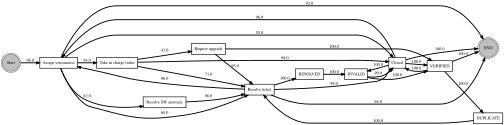

In [ ]:
# Getting links and probabilities for trainPred
probs_O, seqs_O = resultGraphing_.decomposeResultProbBias(trainPred)
link_O, probabilities_O, sequences_O = resultGraphing_.linkAndProbabilities(probs_O)
resultGraphing_.drawGraph(link_O, probabilities_O)


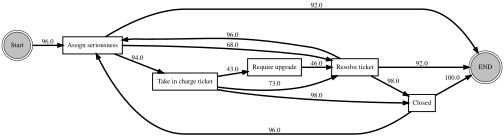

In [ ]:
# Getting links and probabilities for testpred
probs_T, seqs_T = resultGraphing_.decomposeResultProbBias(testPred)
link_T, probabilities_T, sequences_T = resultGraphing_.linkAndProbabilities(probs_T)
resultGraphing_.drawGraph(link_T, probabilities_T, 1)

In [ ]:
#Initialize an empty performance class
perf = performance()

In [ ]:
events = list(Y.columns.values)
h1 = perf.getMatrix([link_T, probabilities_T], events, None)
h2 = perf.getMatrix([link_O, probabilities_O], events, None)

In [ ]:
events = list(Y.columns.values)
h1 = perf.getMatrixV2([seqs_T, probabilities_T], events)
h2 = perf.getMatrixV2([seqs_O, probabilities_O], events)

TypeError: ignored

In [ ]:
result = perf.getAdjacency(h1, h2, len(events))
print(result)

26
15.59
14.0
[0.5996153846153847, 0.5384615384615384]


In [ ]:
h1

In [ ]:
h2